# 13 - Cut-off Strategy

Turn the validated scorecard (`12_validation`) into a three-way decision:

| Decision | Rule | Meaning |
|---|---|---|
| **Approve** | `score >= APPROVE_FROM` | Automatic approval |
| **Review** | in between | Manual underwriting |
| **Reject** | `score < REJECT_BELOW` | Automatic rejection |

The Review band catches borderline applicants, including groups the scorecard is known to mis-calibrate (`11_fairness`: under-25s and women get a predicted PD above their observed default rate, calibration ratio < 1, i.e. scores that are too low). By gender the bias is small (women about 2 points too low, men about 4 points too high, ratio 1.12) and women still score higher than men on average; the age bias (under-25s about 10 points too low) is the one the Review band mainly targets. The Review band cannot correct scores that are too high. Steps:

1. Read the thresholds in PD terms.
2. Compare candidate band schemes (volume vs risk).
3. Fix the scheme and summarise each band.
4. Check how the bands fall across age and gender groups.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

# Add project root to sys.path so `src` can be imported from the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.fairness import age_bands
from src.scorecard import assign_decision, decision_summary, pd_to_score, score_to_pd

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Candidate schemes (reject_below, approve_from); equal values = plain approve/reject at that cut-off
SCHEMES = [(550, 550), (545, 555), (540, 560), (530, 560), (540, 570)]
# Chosen scheme (multiples of 10 so the chart buckets line up)
REJECT_BELOW, APPROVE_FROM = 540, 560

# Decision colors (fixed meaning across the project), muted ink for reference lines
DECISION_COLORS = {"Reject": "#eb6834", "Review": "#eda100", "Approve": "#1baf7a"}
MUTED, GRID = "#8a8985", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
})

## 2. Load scorecard scores (test)

In [2]:
scaling = pd.read_csv(OUTPUT_DIR / "score_scaling.csv", index_col=0).iloc[:, 0]
factor, offset = scaling["factor"], scaling["offset"]

pd_all = pd.read_pickle(DATA_DIR / "pd_test_all_models.pkl")
y = pd_all["TARGET"]
score = pd_to_score(pd_all["Scorecard"], factor, offset)

test = pd.read_pickle(DATA_DIR / "test.pkl").loc[score.index]
print(f"Test: {len(score):,} | default rate {y.mean():.2%} | score mean {score.mean():.0f} "
      f"(p5 {score.quantile(0.05):.0f}, p95 {score.quantile(0.95):.0f})")

Test: 61,503 | default rate 8.07% | score mean 567 (p5 523, p95 610)


## 3. Thresholds in PD terms

Each score maps to a PD (`score_to_pd`). A natural anchor is the portfolio default rate (8.07%): approve automatically only applicants clearly safer than average, reject only those clearly riskier.

In [3]:
anchors = pd.Series(range(520, 591, 10), name="score")
pd.DataFrame({
    "pd": score_to_pd(anchors, factor, offset).to_numpy(),
    "odds_good_bad": (1 / score_to_pd(anchors, factor, offset) - 1).to_numpy(),
    "share_at_or_above": [(score >= s).mean() for s in anchors],
}, index=anchors).style.format({"pd": "{:.2%}", "odds_good_bad": "{:.1f}", "share_at_or_above": "{:.1%}"})

,pd,odds_good_bad,share_at_or_above
score,,,
520,24.24%,3.1,96.0%
530,18.45%,4.4,91.5%
540,13.79%,6.3,84.2%
550,10.16%,8.8,73.6%
560,7.41%,12.5,60.7%
570,5.35%,17.7,46.5%
580,3.85%,25.0,32.2%
590,2.75%,35.4,19.7%


## 4. Compare band schemes

For each scheme: share of applicants and default rate in every band, and share of all bads that get through automatic approval (`bads_auto_approved`). A wider Review band lowers both risks but costs manual work.

In [4]:
def scheme_row(reject_below: float, approve_from: float) -> pd.Series:
    """Flatten the decision summary of one scheme into one row."""
    t = decision_summary(y, assign_decision(score, reject_below, approve_from))
    row = {f"{d.lower()}_{c}": t.loc[d, c] for d in t.index for c in ("share", "bad_rate")}
    row["bads_auto_approved"] = t.loc["Approve", "bads_share"]
    return pd.Series(row)


schemes = pd.DataFrame({f"{r}/{a}": scheme_row(r, a) for r, a in SCHEMES}).T
schemes.index.name = "reject_below/approve_from"
schemes.style.format("{:.1%}", na_rep="-")

,reject_share,reject_bad_rate,review_share,review_bad_rate,approve_share,approve_bad_rate,bads_auto_approved
reject_below/approve_from,,,,,,,
550/550,26.4%,17.7%,0.0%,-,73.6%,4.6%,42.1%
545/555,20.8%,19.3%,11.9%,10.6%,67.4%,4.2%,34.7%
540/560,15.8%,21.5%,23.4%,10.1%,60.7%,3.8%,28.5%
530/560,8.5%,26.3%,30.7%,11.5%,60.7%,3.8%,28.5%
540/570,15.8%,21.5%,37.7%,8.7%,46.5%,3.0%,17.5%


## 5. Chosen scheme

In [5]:
decision = assign_decision(score, REJECT_BELOW, APPROVE_FROM)
bands = decision_summary(y, decision)
bands["score_range"] = [f"< {REJECT_BELOW}", f"{REJECT_BELOW}-{APPROVE_FROM - 1}", f">= {APPROVE_FROM}"]
bands["pd_range"] = [
    f"> {score_to_pd(pd.Series([REJECT_BELOW]), factor, offset).iloc[0]:.1%}",
    f"{score_to_pd(pd.Series([APPROVE_FROM]), factor, offset).iloc[0]:.1%}-"
    f"{score_to_pd(pd.Series([REJECT_BELOW]), factor, offset).iloc[0]:.1%}",
    f"<= {score_to_pd(pd.Series([APPROVE_FROM]), factor, offset).iloc[0]:.1%}",
]
bands.style.format({"share": "{:.1%}", "bad_rate": "{:.2%}", "bads_share": "{:.1%}"})

,n,share,n_bad,bad_rate,bads_share,score_range,pd_range
decision,,,,,,,
Reject,9741,15.8%,2090,21.46%,42.1%,< 540,> 13.8%
Review,14415,23.4%,1460,10.13%,29.4%,540-559,7.4%-13.8%
Approve,37347,60.7%,1415,3.79%,28.5%,>= 560,<= 7.4%


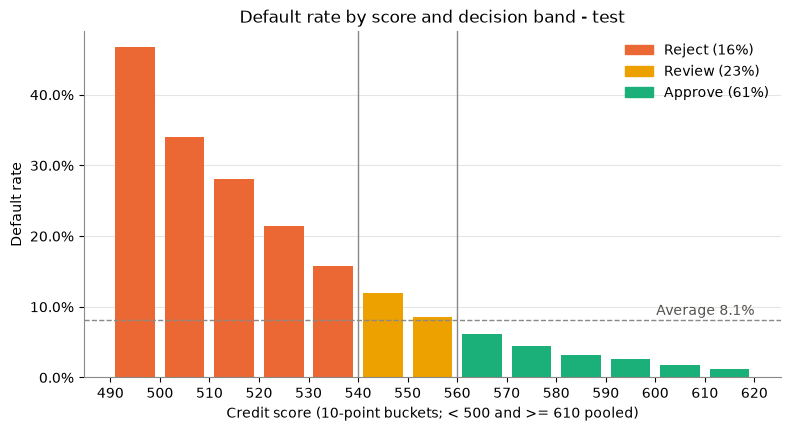

In [6]:
# Default rate by 10-point score bucket, coloured by decision (tails pooled)
lo, hi = 490, 620
bucket = (score.clip(lo, hi - 0.01) // 10 * 10).astype(int)
by_bucket = y.groupby(bucket).agg(["mean", "size"])
colors = [DECISION_COLORS[d] for d in assign_decision(pd.Series(by_bucket.index, dtype=float), REJECT_BELOW, APPROVE_FROM)]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(by_bucket.index + 5, by_bucket["mean"], width=8, color=colors)
ax.axhline(y.mean(), color=MUTED, linestyle="--", linewidth=1)
ax.annotate(f"Average {y.mean():.1%}", (hi, y.mean()), xytext=(0, 4), textcoords="offset points",
            ha="right", color="#52514e")
for x in sorted({REJECT_BELOW, APPROVE_FROM}):
    ax.axvline(x, color=MUTED, linewidth=1)
ax.set(xlabel=f"Credit score (10-point buckets; < {lo + 10} and >= {hi - 10} pooled)", ylabel="Default rate",
       title="Default rate by score and decision band - test", xticks=range(lo, hi + 1, 10))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=c, label=f"{d} ({bands.loc[d, 'share']:.0%})") for d, c in DECISION_COLORS.items()],
          frameon=False)
fig.savefig(OUTPUT_DIR / "decision_bands.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Bands by age and gender

Share of each group in each band, and the group's default rate. A group with a high Review share but a near-average default rate shows where manual review is most likely to overturn the score.

In [7]:
groups = {"age_band": age_bands(test["AGE_YEARS"]), "gender": test["CODE_GENDER"]}

parts = []
for name, g in groups.items():
    t = pd.crosstab(g, decision, normalize="index")
    t.columns = t.columns.astype(str)  # plain columns so new ones can be added
    t["default_rate"] = y.groupby(g, observed=True).mean()
    t["n"] = g.value_counts()
    parts.append(t.rename_axis("group").assign(attribute=name).set_index("attribute", append=True).swaplevel())
by_group = pd.concat(parts)
by_group.style.format({d: "{:.1%}" for d in DECISION_COLORS} | {"default_rate": "{:.2%}", "n": "{:,.0f}"})

## 7. Save artifacts

In [8]:
bands.to_csv(OUTPUT_DIR / "decision_bands.csv")
schemes.to_csv(OUTPUT_DIR / "decision_schemes.csv")
by_group.to_csv(OUTPUT_DIR / "decision_by_group.csv")
print("Saved decision_bands.csv, decision_schemes.csv, decision_by_group.csv, decision_bands.png")

Saved decision_bands.csv, decision_schemes.csv, decision_by_group.csv, decision_bands.png


## 8. Conclusions

**Chosen scheme 540 / 560.** Thresholds map to PD 13.8% and 7.4%: approve automatically only applicants safer than the portfolio average (8.07%), reject automatically only those at 1.7× the average or worse.

| Band | Score | PD | Share | Default rate | Share of all bads |
|---|---|---|---|---|---|
| Reject | < 540 | > 13.8% | 15.8% | 21.5% | 42% |
| Review | 540-559 | 7.4-13.8% | 23.4% | 10.1% | 29% |
| Approve | >= 560 | <= 7.4% | 60.7% | 3.8% | 28% |

**Trade-off.** Compared with a single cut-off at 550, the Review band cuts the bads that are approved automatically from 42% to 28% and the approved default rate from 4.6% to 3.8%, at the cost of reviewing 23% of applicants by hand. If review capacity is limited, 545 / 555 reviews 12% and still cuts automatically approved bads to 35%.

**Groups.** Under-25s: 49% rejected, 33% reviewed, 18% approved, although their observed default rate (11.7%) corresponds to a score of about 545, inside the Review band. The ~10-point under-scoring pushes half of them straight into Reject, where manual review never sees them. A policy rule (e.g. route under-25s scoring 530-559 to Review) would fix this without changing the model. By gender, men are rejected more often (20% vs 14%) mainly because their risk is genuinely higher (10.2% vs 7.0%); the model bias is only 2-4 points.